<a href="https://colab.research.google.com/github/Likkesh-S/Developer-Flow-State-Cognitive-Load-Analytics/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()
df = pd.read_csv("developer_activity.csv")

df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Dataset shape:", df.shape)
display(df.head())

Saving developer_activity.csv to developer_activity.csv
Dataset shape: (32, 9)


,timestamp,developer_id,coding_minutes,interruption_count,context_switches,task_complexity,break_minutes,focus_score,cognitive_load_score
0,2026-10-20 09:00:00,DEV001,42,1,2,3,5,78,35
1,2026-10-20 10:00:00,DEV001,50,0,1,4,5,88,42
2,2026-10-20 11:00:00,DEV001,35,3,5,4,5,61,68
3,2026-10-20 12:00:00,DEV001,20,2,3,2,15,65,40
4,2026-10-20 13:00:00,DEV001,45,1,2,5,10,76,63


In [2]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

display(df.describe())

Missing values:
timestamp               0
developer_id            0
coding_minutes          0
interruption_count      0
context_switches        0
task_complexity         0
break_minutes           0
focus_score             0
cognitive_load_score    0
dtype: int64
Duplicate rows: 0


,timestamp,coding_minutes,interruption_count,context_switches,task_complexity,break_minutes,focus_score,cognitive_load_score
count,32,32.000000,32.000000,32.000000,32.00000,32.000000,32.000000,32.000000
mean,2026-10-21 00:30:00,37.156250,1.843750,3.218750,3.46875,8.593750,71.218750,52.125000
min,2026-10-20 09:00:00,18.000000,0.000000,1.000000,2.00000,5.000000,49.000000,31.000000
25%,2026-10-20 12:45:00,30.750000,1.000000,2.000000,3.00000,5.000000,61.750000,38.000000
50%,2026-10-21 00:30:00,38.500000,2.000000,3.000000,3.50000,7.500000,70.000000,48.000000
75%,2026-10-21 12:15:00,45.000000,2.250000,4.250000,4.00000,10.000000,80.500000,63.250000
max,2026-10-21 16:00:00,50.000000,5.000000,7.000000,5.00000,20.000000,92.000000,85.000000
std,NaN,9.463374,1.322495,1.717732,0.91526,4.620148,12.416779,16.219761


In [3]:
summary = df.groupby("developer_id").agg(
    avg_coding_minutes=("coding_minutes", "mean"),
    avg_interruptions=("interruption_count", "mean"),
    avg_context_switches=("context_switches", "mean"),
    avg_focus_score=("focus_score", "mean"),
    avg_cognitive_load=("cognitive_load_score", "mean")
).round(2)

display(summary)

,avg_coding_minutes,avg_interruptions,avg_context_switches,avg_focus_score,avg_cognitive_load
developer_id,,,,,
DEV001,38.12,1.62,2.88,72.94,51.00
DEV002,36.19,2.06,3.56,69.50,53.25


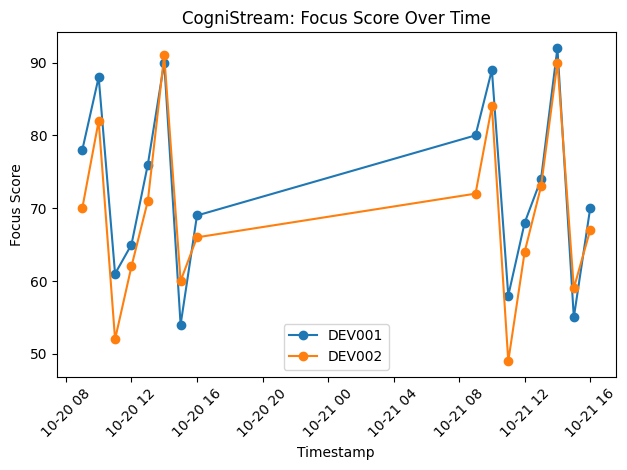

In [4]:
for developer, group in df.groupby("developer_id"):
    group = group.sort_values("timestamp")
    plt.plot(
        group["timestamp"],
        group["focus_score"],
        marker="o",
        label=developer
    )

plt.title("CogniStream: Focus Score Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Focus Score")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

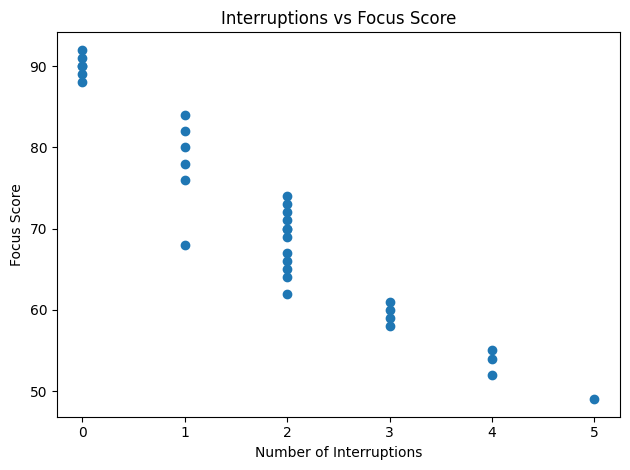

In [6]:
plt.scatter(
    df["interruption_count"],
    df["focus_score"]
)

plt.title("Interruptions vs Focus Score")
plt.xlabel("Number of Interruptions")
plt.ylabel("Focus Score")
plt.tight_layout()
plt.show()